# Lecture 25 - AI Orchestration and Agent Frameworks

[![View notebook on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/Lecture_25-AI_Orchestration.ipynb)
[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/Lecture_25-AI_Orchestration.ipynb)
[![View on Website](https://img.shields.io/static/v1.svg?logo=quarto&label=Web&message=View%20on%20Website&color=blue)](https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/Lecture_25-AI_Orchestration.html)

<a id='top'></a>

- [25.1 Introduction to AI Orchestration](#25.1-introduction-to-ai-orchestration)
    - [25.1.1 Workflows versus Agents](#25.1.1-workflows-versus-agents)
    - [25.1.2 The Agent Harness](#25.1.2-the-agent-harness)
- [25.2 Workflow Orchestration Patterns](#25.2-workflow-orchestration-patterns)
    - [25.2.1 Prompt Chaining](#25.2.1-prompt-chaining)
    - [25.2.2 Routing](#25.2.2-routing)
    - [25.2.3 Parallelization](#25.2.3-parallelization)
    - [25.2.4 Orchestrator-Workers and Evaluator-Optimizer](#25.2.4-orchestrator-workers-and-evaluator-optimizer)
- [25.3 Tool Calling and the Agent Harness](#25.3-tool-calling-and-the-agent-harness)
    - [25.3.1 Function Calling](#25.3.1-function-calling)
    - [25.3.2 A Minimal Agent Harness](#25.3.2-a-minimal-agent-harness)
    - [25.3.3 Model Context Protocol](#25.3.3-model-context-protocol)
- [25.4 Memory](#25.4-memory)
    - [25.4.1 Short-Term Memory](#25.4.1-short-term-memory)
    - [25.4.2 Long-Term Memory](#25.4.2-long-term-memory)
- [25.5 LangChain and LangGraph](#25.5-langchain-and-langgraph)
    - [25.5.1 LangChain Components](#25.5.1-langchain-components)
    - [25.5.2 Building a ReAct Agent with LangGraph](#25.5.2-building-a-react-agent-with-langgraph)
    - [25.5.3 An Evaluator-Optimizer Workflow](#25.5.3-an-evaluator-optimizer-workflow)
- [25.6 CrewAI](#25.6-crewai)
- [25.7 AutoGen](#25.7-autogen)
- [25.8 Choosing a Framework](#25.8-choosing-a-framework)
- [25.9 Production Considerations](#25.9-production-considerations)
- [References](#references)

<a id="25.1-introduction-to-ai-orchestration"></a>

## 25.1 Introduction to AI Orchestration

In the previous lecture, we built agents with the `smolagents` framework, and we saw that an agent is an LLM that operates inside a control loop: it reasons about a task, calls tools, observes the results, and repeats until the task is completed. And while building a single agent that answers a question with a web search is relatively simple, building a system with several agents that combines LLM calls, tools, data sources, and memory is considerably more difficult.

**AI orchestration** refers to the coordination of these components into a system that performs a larger task. An orchestration layer decides which model is called and when, which tools are available, how intermediate results are passed between steps, what is remembered between conversations, and when the system should stop or ask a human for help.

In this lecture, we will first study the main building blocks of orchestration, namely workflow patterns, tool integration, the agent harness, and memory. We will implement them in plain Python first, and afterwards, we will see how popular frameworks like LangChain, LangGraph, CrewAI, and AutoGen implement these ideas into reusable modules.

<a id="25.1.1-workflows-versus-agents"></a>

### 25.1.1 Workflows versus Agents

LLM-based systems can be categorized based on how much control is given to the LLM.

- **Workflows** are systems where LLMs and tools are orchestrated through *predefined code paths*. In this case, the developer decides the sequence of steps in advance, e.g., "first summarize the document, then translate the summary, then format it as an email". The LLM performs each step, but it does not decide what the next step is.
- **Agents** are systems where the LLM *dynamically directs its own process* and tool usage. The developer provides a goal and a set of tools, and the LLM decides which tools to call, in what order, and when the task is finished.

Workflows are predictable, easier to test, and faster. Agents are flexible and can handle open-ended problems where the number of steps cannot be known in advance, but they are harder to debug and their cost and latency are less predictable.

A practical recommendation is to start with the simplest solution that works and includes only a single LLM call. A workflow should be added only when a single call is not enough, and an agent should be used only when the flexibility of autonomous decision-making is needed.

On the other hand, the difference between workflows and agents is becoming less strict. For example, with *dynamic workflows* in Claude Code, the agent writes a workflow script customized for a task, and the script then coordinates the sub-agents with predefined code paths [14]. E.g., a script can use one sub-agent per file to review a codebase, and then use additional sub-agents to verify the findings. In this case, the LLM designs the structure of the workflow, but the execution of the workflow is deterministic.

<a id="25.1.2-the-agent-harness"></a>

### 25.1.2 The Agent Harness

An LLM can be considered a function that maps a sequence of tokens to the next token. The mapping function cannot run code, read files, or remember anything between calls by itself. Turning an LLM into an agent is done by the software that surrounds the LLM, which is referred to as the **agent harness**.

The harness typically includes the following components:

- **Agent loop**: calls the model, checks whether the response contains tool calls, executes them, appends the results to the conversation, and calls the model again.
- **Tool registry and dispatch**: describes the available tools to the model (names, descriptions, input schemas), and maps the tool calls produced by the model to actual Python functions or API requests.
- **Context management**: decides what goes into the model's context window at each step, such as the system prompt, conversation history, tool results, and retrieved documents. When the context grows too long, the harness trims or summarizes older content, often called *compaction*.
- **Memory**: stores information that should persist for more than a single conversation, such as user preferences or information learned in previous sessions.
- **Guardrails and permissions**: limits the number of steps, validates tool inputs, runs code in sandboxes, and requires human approval for actions such as deleting files or sending emails.
- **Observability**: logs every model call and tool call, with token counts, latency, and errors, so that developers can debug and evaluate the agent.

A useful way to think about modern agentic systems is **agent = model + harness**. The same LLM can perform very differently depending on the quality of its harness. Coding assistants such as Claude Code, OpenAI Codex, and Cursor are examples of carefully engineered harnesses around frontier LLMs, where most of the engineering effort goes into context management, tool design, and safety, rather than into the model itself.

Agentic frameworks covered in this lecture such as LangGraph, CrewAI, and AutoGen, can be understood as libraries that provide developed harness components, so that developers do not need to write them from scratch.

**Harness Design Patterns**

Although harnesses for different applications vary in their details, most of them are built from a few recurring design patterns [9]:

- *Workflow loop*: the agent repeatedly plans, executes an action, observes or tests the outcome, and improves its approach until the goal is reached, asking the user for clarification when needed. The figure below shows this loop for a coding agent, where running the tests is used to check whether the task is completed.
- *File system as persistent memory*: long-running tasks produce more information than can fit in the context window. This can include plans, experiment logs, code changes, intermediate results, etc. Instead of keeping everything in the context, the harness lets the agent write its state to files and read it back when needed.
- *Sub-agents and background jobs*: the main agent can delegate subtasks to sub-agents, each running in its own separate context, or launch long-running jobs in the background. This allows parallel work and keeps the main context free from the details of the subtasks. Storing the outputs as files and logs makes the work easier to track, and allows recovering after interruptions. Sub-agents are usually *bounded*, i.e., they receive enough context to complete their subtask, but run with tighter limits, such as read-only access to files, or a limit on how many further sub-agents they can launch [12].

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/images/coding_agent_harness_loop.png" width="700">

*Figure: The workflow loop of a coding agent harness.* Source [9].

Coding agents such as Claude Code, Codex, and Cursor have converged on a similar set of tools, which illustrates what a mature harness provides to the model [9]:

| Tool category | Examples | Purpose |
|---------------|----------|---------|
| File discovery | `glob`, `grep`, `ls` | Find relevant files in a project |
| File reading | `read` | Load file contents into the context |
| File editing | `write`, `edit`, `apply_patch` | Create files, or replace exact text in existing files |
| Shell | `bash`, `PowerShell` | Run programs, tests, and git commands |
| Web | `web_search`, `web_fetch` | Search for and read online information |
| External context | MCP tools, skills | Connect to external systems and load task-specific instructions |
| Background jobs | Scheduling tools (e.g., cron jobs) | Run tasks later or periodically |
| Agent delegation | `spawn_agent`, `wait_agent` | Start sub-agents and collect their results |

Most of these tools are general-purpose, and instead of providing a separate tool for every possible action, the harness gives the model a small set of flexible tools, such as a shell, and relies on the model's ability to combine them.

<a id="25.2-workflow-orchestration-patterns"></a>

## 25.2 Workflow Orchestration Patterns

Most LLM applications can be built by combining a small number of workflow patterns. In this section, we will implement several of them in plain Python.

We will use the Hugging Face Inference Providers service, which provides access to open-source LLMs through an OpenAI-compatible API at the address `https://router.huggingface.co/v1`. This will allow us to use the `openai` Python package with open models such as Qwen, by changing only the `base_url` and the API key. A Hugging Face access token is required, and similarly to the previous lecture, we will load it from Colab Secrets.

Note that the free monthly quota of Hugging Face Inference Providers is limited. If the quota is exceeded, the same code can be used with a paid OpenAI key by removing the `base_url` argument and changing the model name, e.g., to `gpt-4o-mini`.

In [7]:
!pip install -q openai sentence-transformers

In [8]:
from openai import OpenAI
from google.colab import userdata

# Get the Hugging Face token from Colab Secrets
token = userdata.get('HF_TOKEN')

# Hugging Face Inference Providers expose an OpenAI-compatible endpoint
HF_BASE_URL = "https://router.huggingface.co/v1"

In [9]:
# The LLM to use is Qwen2.5-72B
MODEL_ID = "Qwen/Qwen2.5-72B-Instruct"

client = OpenAI(base_url=HF_BASE_URL, api_key=token)

The following helper function sends a single prompt to the LLM and returns the text of the response. We will use it as the basic building block for the workflow patterns.

In [10]:
def llm(prompt, system="You are a helpful assistant.", temperature=0.2):
    # Send one prompt to the LLM and return the text response
    response = client.chat.completions.create(
        model=MODEL_ID,
        messages=[{"role": "system", "content": system},
                  {"role": "user", "content": prompt}],
        temperature=temperature,
        max_tokens=512)
    return response.choices[0].message.content

In [11]:
print(llm("In one sentence, what is a data pipeline?"))

A data pipeline is a series of processes that extract, transform, and load data from various sources to a destination for analysis or further processing.


<a id="25.2.1-prompt-chaining"></a>

### 25.2.1 Prompt Chaining

**Prompt chaining** decomposes a task into a fixed sequence of steps, where the output of each LLM call becomes the input to the next call. Between the steps, we can add programmatic checks (called *gates*) to verify that the intermediate output is acceptable before continuing.

In the example below, the first call extracts the key findings from a short report, a gate checks that the findings are in the expected bullet format, and the second call rewrites the findings as an email to a non-technical manager.

In [12]:
report = '''Our churn model was retrained on Q3 data. Recall on the churn class improved
from 0.61 to 0.74 after adding the support-ticket features, while precision dropped
slightly from 0.70 to 0.68. Customers with more than three support tickets in a month
are 2.5 times more likely to churn. Inference latency stayed under 40 ms.'''

# Step 1: extract key findings
findings = llm(f"Extract the three most important findings from this report as a bullet list "
               f"using '-' bullets, and nothing else:\n\n{report}")
print("STEP 1 OUTPUT:\n", findings)

# Gate: check the format before continuing
bullets = [line for line in findings.splitlines() if line.strip().startswith("-")]
assert len(bullets) >= 3, "Gate failed: expected at least three bullet points"

# Step 2: rewrite for a non-technical audience
email = llm(f"Write a short email (under 120 words) to a non-technical manager "
            f"summarizing these findings:\n\n{findings}")
print("\nSTEP 2 OUTPUT:\n", email)

STEP 1 OUTPUT:
 - Recall on the churn class improved from 0.61 to 0.74 after adding support-ticket features.
- Customers with more than three support tickets in a month are 2.5 times more likely to churn.
- Inference latency stayed under 40 ms.

STEP 2 OUTPUT:
 Subject: Update on Churn Prediction Model

Hi [Manager's Name],

I wanted to share some positive updates on our churn prediction model. After incorporating support-ticket data, recall for the churn class improved from 0.61 to 0.74. We also found that customers with more than three support tickets in a month are 2.5 times more likely to churn. Additionally, the model's inference latency remains under 40 ms, ensuring fast and efficient predictions.

Best regards,
[Your Name]


<a id="25.2.2-routing"></a>

### 25.2.2 Routing

**Routing** classifies an input and directs it to a specialized follow-up step. This allows using different prompts, tools, or even different models for different types of requests. For instance, simple questions can be routed to a small, inexpensive model, and difficult questions to a larger model.

In the example, an LLM first classifies a student's message into one of three categories, and a different system prompt is used to answer each category.

In [13]:
ROUTES = {
    "coding": "You are a Python tutor. Answer with a short explanation and a code example, in under 150 words.",
    "concept": "You are a data science instructor. Explain the concept intuitively, without code, in under 150 words.",
    "logistics": "You are a course assistant. If you do not know course-specific details, "
                 "tell the student to check the syllabus.",
}

def route_and_answer(message):
    # Step 1: classify the message
    category = llm(f"Classify this student message into exactly one category: "
                   f"coding, concept, or logistics. Reply with the category only.\n\n{message}",
                   temperature=0).strip().lower()
    if category not in ROUTES:
        category = "concept"   # fallback route
    # Step 2: answer with the specialized prompt
    answer = llm(message, system=ROUTES[category])
    return category, answer

for msg in ["How do I drop rows with missing values in a pandas DataFrame?",
            "Why does regularization reduce overfitting?",
            "When is Homework 6 due?"]:
    category, answer = route_and_answer(msg)
    print(f"[{category}] {msg}\n{answer}\n" + "-" * 80)

[coding] How do I drop rows with missing values in a pandas DataFrame?
To drop rows with missing values in a pandas DataFrame, you can use the `dropna()` method. This method removes any row that has at least one missing value (NaN). You can specify additional parameters like `axis`, `how`, `thresh`, and `subset` to control the behavior of row removal.

Here's a simple example:

```python
import pandas as pd
import numpy as np

# Create a DataFrame with some missing values
data = {'A': [1, 2, np.nan], 'B': [5, np.nan, np.nan], 'C': [9, 10, 11]}
df = pd.DataFrame(data)

# Drop rows with any missing values
df_cleaned = df.dropna()

print(df_cleaned)
```

In this example, `df.dropna()` removes the rows where at least one value is missing, resulting in a DataFrame with only the rows that have complete data.
--------------------------------------------------------------------------------
[concept] Why does regularization reduce overfitting?
Regularization reduces overfitting by adding a pena

<a id="25.2.3-parallelization"></a>

### 25.2.3 Parallelization

**Parallelization** runs several LLM calls at the same time and combines their outputs. There are two common variants:

- *Sectioning*: a task is split into independent subtasks that run in parallel, e.g., reviewing a piece of code for correctness, readability, and security at the same time.
- *Voting*: the same task is run several times, and the outputs are aggregated (e.g., by majority vote), to obtain a more reliable answer.

Because each LLM call spends most of its time waiting for the remote server, we can run the calls concurrently with a thread pool, which reduces the total latency.

In [15]:
from concurrent.futures import ThreadPoolExecutor

code_snippet = '''
def load(path):
    import pickle
    data = pickle.load(open(path, "rb"))
    total = 0
    for i in range(len(data)):
        total = total + data[i]
    return total / len(data)
'''

# Consider three aspects: correctness, readability, security
aspects = {
    "correctness": "Review this code only for correctness bugs and edge cases.",
    "readability": "Review this code only for readability and Pythonic style.",
    "security": "Review this code only for security issues.",
}

# Generate a review for each aspect
def review(aspect):
    return aspect, llm(f"{aspects[aspect]} Give at most three short bullet points.\n{code_snippet}")

# Sectioning: run the three reviews in parallel
with ThreadPoolExecutor(max_workers=3) as pool:
    reviews = dict(pool.map(review, aspects))

In [19]:
# Print the responses for each aspect
for aspect, text in reviews.items():
    print(f"=== {aspect.upper()} ===\n{text}\n")

=== CORRECTNESS ===
- **File Handling**: The file opened with `open(path, "rb")` is not closed, which can lead to resource leaks. Consider using a context manager (`with` statement) to ensure the file is properly closed.
- **Empty Data**: If `data` is empty, `len(data)` will be 0, leading to a division by zero error. Handle this case by checking if `data` is empty before performing the division.
- **Pickle Security**: Using `pickle` to load data from an untrusted source can be a security risk, as it can execute arbitrary code. Ensure the source of the file is trusted.

=== READABILITY ===
- Import statements should be at the top of the file for better readability.
- Use a context manager (`with` statement) to handle file operations, ensuring the file is properly closed.
- Simplify the loop using a list comprehension or the `sum` function for better readability and conciseness.

```python
import pickle

def load(path):
    with open(path, "rb") as file:
        data = pickle.load(file)


<a id="25.2.4-orchestrator-workers-and-evaluator-optimizer"></a>

### 25.2.4 Orchestrator-Workers and Evaluator-Optimizer

Two additional patterns give the LLM more control over the workflow, and they are a step toward agents.

- **Orchestrator-workers**: A central LLM (the orchestrator) analyzes the task, decides which subtasks are needed, delegates them to worker LLMs, and generates the results. Differently from sectioning, the subtasks are not predefined by the developer but are determined by the orchestrator at run time. The manager agent with managed agents in Lecture 24 followed this pattern.
- **Evaluator-optimizer**: One LLM generates a response, and a second LLM evaluates it and provides feedback. The loop repeats until the evaluator is satisfied or a maximum number of iterations is reached. This pattern is effective when clear evaluation criteria exist, e.g., for translation, writing, or code that must pass tests.

The reason for dividing a task across several LLM calls with separate contexts instead of asking one agent to do everything is because when a single agent works on a long and complex task within one context window, the following failure modes are possible [14]:

- *Agentic laziness*: the agent stops after partial progress and states that the task is completed, e.g., after reviewing 20 out of 50 files.
- *Self-preferential bias*: the agent favors its own results when it is asked to verify or judge them.
- *Goal drift*: the agent gradually loses track of the original objective over many steps, especially after compaction, since each summary loses some information and important details can be lost.

Workflows reduce these problems by giving each LLM call a focused goal and a clean context. The basic patterns can also be combined into more specialized ones, such as:

- *Adversarial verification*: a separate LLM call checks each result against a set of criteria, to avoid self-preferential bias.
- *Generate-and-filter*: generate many candidate solutions, then remove duplicates and keep only those that pass a rubric or a verification step.
- *Tournament*: several LLM calls solve the same task with different approaches, and a judge compares the results in pairs until a winner remains. Comparing two results is often more reliable than assigning absolute scores to each result.
- *Loop until done*: when the amount of work is not known in advance, keep launching new LLM calls until a stop condition is met, e.g., no new findings are reported.

These patterns use considerably more tokens, so they should be applied only when a single LLM call or a single agent is not sufficient.

We will implement an evaluator-optimizer loop with LangGraph later in this lecture.

<a id="25.3-tool-calling-and-the-agent-harness"></a>

## 25.3 Tool Calling and the Agent Harness

Tools allow an LLM to interact with the outside world, such as search the web, query a database, run code, call an API, or read a file. In Lecture 24, we defined tools with the `@tool` decorator of `smolagents`, and the framework did the rest, including it described the tools to the model, parsed the model's requests, executed the tools, and repeated the loop. In this section, we will look at what the framework does. We will first see how tool calling works at the level of the API, and afterwards we will write a minimal agent harness.

<a id="25.3.1-function-calling"></a>

### 25.3.1 Function Calling

Modern LLMs are fine-tuned to support **function calling** (also known as *tool calling*). The process is as follows:

1. The developer describes each tool with a name, a natural-language description, and a JSON Schema of its input parameters, and sends these descriptions to the model together with the conversation.
2. If the model decides that a tool is needed, instead of a text answer it returns a structured *tool call*, containing the tool name and the arguments as a JSON object.
3. The application (not the model) executes the tool, and sends the result back to the model as a message with the role `tool`.
4. The model uses the tool result to produce the final answer, or requests another tool call.

It is important to note that the LLM doesn't execute anything itself. It only produces text that describes which function should be called. The harness is responsible for parsing the request, validating it, executing it, and returning the result.

The next cell defines two simple Python functions and their JSON Schema descriptions in the format expected by OpenAI-compatible APIs.

In [20]:
import json, math

def get_weather(city: str) -> str:
    # A mock weather service (a real tool would call a weather API)
    fake_data = {"moscow": "Sunny, 18 C", "boise": "Cloudy, 12 C", "seattle": "Rain, 10 C"}
    return fake_data.get(city.lower(), f"No weather data available for {city}")

def calculator(expression: str) -> str:
    # Evaluate a math expression, allowing only functions from the math module.
    # Note that eval() is not a real sandbox, it is for demonstration only
    allowed = {name: getattr(math, name) for name in dir(math) if not name.startswith("_")}
    return str(eval(expression, {"__builtins__": {}}, allowed))

# Tool registry: maps tool names to Python functions
TOOLS = {"get_weather": get_weather, "calculator": calculator}

# Tool descriptions sent to the LLM
tool_schemas = [
    {"type": "function",
     "function": {
         "name": "get_weather",
         "description": "Get the current weather for a city.",
         "parameters": {"type": "object",
                        "properties": {"city": {"type": "string", "description": "City name, e.g. Boise"}},
                        "required": ["city"]}}},
    {"type": "function",
     "function": {
         "name": "calculator",
         "description": "Evaluate a mathematical expression written in Python syntax, e.g. 'sqrt(2) * 10'.",
         "parameters": {"type": "object",
                        "properties": {"expression": {"type": "string", "description": "The expression to evaluate"}},
                        "required": ["expression"]}}},
]

Let's send a question to the model together with the tool descriptions and check the response. Notice that the response does not contain a text answer. Instead, `message.tool_calls` contains the name of the tool and its arguments in JSON format.

In [21]:
response = client.chat.completions.create(
    model=MODEL_ID,
    messages=[{"role": "user", "content": "What is the weather in Boise right now?"}],
    tools=tool_schemas,
    tool_choice="auto")

message = response.choices[0].message
print("Text content:", message.content)
for call in message.tool_calls or []:
    print("Tool call:", call.function.name, call.function.arguments)

Text content: None
Tool call: get_weather {"city": "Boise"}


<a id="25.3.2-a-minimal-agent-harness"></a>

### 25.3.2 A Minimal Agent Harness

We now have all components to write an agent harness. The function `run_agent()` below implements the agent loop described in the above Section 25.1.2:

- It keeps the conversation in the `messages` list, which is the agent's short-term memory.
- At each step, it calls the model with the conversation and the tool descriptions.
- If the model returns tool calls, the harness executes each one, catches any errors, and appends the results to the conversation as `tool` messages. Returning the error message to the model (instead of crashing) allows the model to correct itself, which is the *Observation* step in the ReAct loop.
- If the model returns a text answer without tool calls, the loop ends.
- The `max_steps` argument is a simple guardrail that prevents infinite loops.

This short function contains the essence of what `smolagents`, LangGraph, and other frameworks do internally.

In [22]:
SYSTEM_PROMPT = ("You are a helpful assistant. Use the available tools when they are needed. "
                 "When you have enough information, answer the user directly.")

def run_agent(user_prompt, max_steps=5, verbose=True):
    messages = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_prompt}]

    # For each step, call the LLM with descriptions of messages and tools
    for step in range(1, max_steps + 1):
        response = client.chat.completions.create(
            model=MODEL_ID, messages=messages, tools=tool_schemas, tool_choice="auto")
        message = response.choices[0].message

        # If tools are not called, the model produced the final answer
        if not message.tool_calls:
            if verbose:
                print(f"[Step {step}] Final answer")
            return message.content

        # Add the assistant's tool request to the conversation
        messages.append(message.model_dump(exclude_none=True))

        # Execute every requested tool and return the results to the model
        for call in message.tool_calls:
            name = call.function.name
            try:
                args = json.loads(call.function.arguments)
                result = TOOLS[name](**args)
            except Exception as e:
                result = f"Error: {type(e).__name__}: {e}"
            if verbose:
                print(f"[Step {step}] {name}({call.function.arguments}) -> {result}")
            messages.append({"role": "tool", "tool_call_id": call.id, "content": str(result)})

    return "Stopped: the maximum number of steps was reached."

In [23]:
answer = run_agent("What is the weather in Moscow and in Seattle? "
                   "Also, what is the temperature difference between them in Fahrenheit?")
print("\n" + answer)

[Step 1] get_weather({"city": "Moscow"}) -> Sunny, 18 C
[Step 1] get_weather({"city": "Seattle"}) -> Rain, 10 C
[Step 2] calculator({"expression": "(18 * 9/5) + 32 - ((10 * 9/5) + 32)"}) -> 14.400000000000006
[Step 2] calculator({"expression": "(18 - 10) * 9/5"}) -> 14.4
[Step 3] Final answer

The temperature difference between Moscow and Seattle is 14.4°F. 

To summarize:
- Moscow: Sunny, 18°C
- Seattle: Rainy, 10°C
- Temperature difference: 14.4°F


In the output, we can see that the model first requests the weather for both cities as two tool calls in Step 1, and then uses the calculator tool to compute the temperature difference. In this run, the model made two calculator calls in Step 2, converting both temperatures to Fahrenheit and computing their difference. The result 14.400000000000006 is a floating-point rounding error instead of 14.4 . Since the model decides which tools to call, the exact sequence of tool calls can differ between runs. A temperature difference of 8 degrees Celsius corresponds to a difference of 14.4 degrees Fahrenheit, since only the scale factor 9/5 applies to differences.

The following figure depicts the agent loop, where the user input is passed to the model, and the model either returns a final response, or requests tool calls, whose results are sent back to the model for the next inference step.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/images/agent_loop.png" width="450">

*Figure: The agent loop.* Source [10].

**From a Minimal to a Production Harness**

In the previous example, the function `run_agent()` executes all tool calls that the model requests. Production harnesses, such as those of coding agents, add several checks between the model's response and the tool execution [12], which can include:

1. *Validate*: is the requested tool in the registry, and are the arguments valid according to its schema?
2. *Approve*: does the action require user approval (e.g., deleting files or running shell commands)? Is the requested file path inside the allowed workspace?
3. *Run*: execute the tool only after the checks have passed.
4. *Clip*: truncate long tool outputs before adding them to the conversation, so that a single result does not fill the context window.

Rejecting invalid or unsafe tool calls before execution gives the model less freedom, but it makes the agent safer and more reliable.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/images/coding_agent_tool_execution.png" width="700">

*Figure: Tool execution in a coding agent harness.* Source [12].

The repository [Mini Coding Agent](https://github.com/rasbt/mini-coding-agent)  [13] contains a complete coding agent written in a single file of plain Python without external dependencies, which implements these checks together with context management, session memory, and sub-agents. It is a valuable resource to check if students would like to see how a full harness is built.

<a id="25.3.3-model-context-protocol"></a>

### 25.3.3 Model Context Protocol

In the previous examples, as tools we used Python functions defined in the same notebook as the agent. In practice, we may want to connect agents to external sources like GitHub, Slack, Google Drive, databases, or internal services. Writing a custom integration for every pair of an agent framework and an external system can be very tedious.

The **Model Context Protocol (MCP)** is an open standard, that was introduced by Anthropic in 2024 and supported by OpenAI, Google, Microsoft, and most agent frameworks, and it standardizes how applications provide tools and data to LLMs. MCP is often described as "a USB-C port for AI applications".

MCP uses a client-server architecture:

- An **MCP server** is a program that exposes capabilities: *tools* (functions the model can call), *resources* (data such as files or database records), and *prompts* (reusable prompt templates).
- An **MCP client** lives inside the host application (e.g., Claude Desktop, an IDE, or our own agent), connects to one or more servers, discovers their tools, and forwards the model's tool calls to them.
- Servers can run locally and communicate through standard input/output (`stdio`), or run remotely and communicate over HTTP.

Once a tool is wrapped as an MCP server, it can be used by any MCP-compatible agent without additional code. Thousands of MCP servers are publicly available.

The next cell creates a small MCP server with the `MCPServer` class from the official `mcp` Python package (this class was called `FastMCP` in older versions). The `@mcp.tool()` decorator turns a Python function into an MCP tool, and similarly to `smolagents`, the type hints and the docstring are used to generate the tool description.

In [24]:
!pip install -q mcp

In [25]:
%%writefile course_server.py
from mcp.server import MCPServer

mcp = MCPServer("course-info")

LECTURES = {21: "Retrieval-Augmented Generation", 22: "Multi-modal Models",
            23: "Reasoning Large Language Models", 24: "Agentic AI",
            25: "AI Orchestration and Agent Frameworks"}

@mcp.tool()
def get_lecture_topic(lecture_number: int) -> str:
    '''Return the topic of a lecture in the Applied Data Science with Python course.'''
    return LECTURES.get(lecture_number, "Unknown lecture number")

@mcp.tool()
def list_lectures() -> list[str]:
    '''List all lectures in the course with their numbers.'''
    return [f"Lecture {n} - {t}" for n, t in LECTURES.items()]

if __name__ == "__main__":
    mcp.run(transport="stdio")

Writing course_server.py


The following cell acts as an MCP client, using the `Client` class of the `mcp` package. It launches the server as a subprocess, discovers the available tools with `list_tools()`, and calls one of them with `call_tool()`. An agent harness would perform the same steps, and pass the discovered tool descriptions to the LLM. Note that MCP clients are asynchronous, which is why the code uses `async with` and `await` (Jupyter notebooks allow `await` directly in a cell). The error output of the server is redirected to a log file, because the standard error stream of a notebook cannot be passed to a subprocess.

In [26]:
from mcp import Client, StdioServerParameters
from mcp.client.stdio import stdio_client

server_params = StdioServerParameters(command="python", args=["course_server.py"])

# The server's error output goes to a log file, because the notebook's
# sys.stderr has no file descriptor and cannot be passed to a subprocess
transport = stdio_client(server_params, errlog=open("course_server.log", "w"))

async with Client(transport) as mcp_client:
    # Discover the tools exposed by the server
    tools = await mcp_client.list_tools()
    for t in tools.tools:
        print(f"{t.name}: {t.description}")

    # Call a tool
    result = await mcp_client.call_tool("get_lecture_topic", {"lecture_number": 21})
    print("\nResult:", result.content[0].text)

get_lecture_topic: Return the topic of a lecture in the Applied Data Science with Python course.
list_lectures: List all lectures in the course with their numbers.

Result: Retrieval-Augmented Generation


Agent frameworks provide adapters that convert MCP tools into their own tool format. For example, the `langchain-mcp-adapters` package loads the tools from MCP servers as LangChain tools, which can then be passed to a LangGraph agent, and `smolagents` provides the `ToolCollection.from_mcp()` method.

<a id="25.4-memory"></a>

## 25.4 Memory

Because LLMs are stateless, each API call is independent, and the model does not remember previous calls. Any form of memory therefore must be implemented by the harness, by deciding what information to place into the context window. Agent memory is commonly divided into short-term and long-term memory.

<a id="25.4.1-short-term-memory"></a>

### 25.4.1 Short-Term Memory

**Short-term memory** (also called *working memory*) is the information within the current conversation or task, which can include past messages, tool calls, and tool results. In our harness, short-term memory was simply the `messages` list.

The difficulty is that the context window is finite, and long conversations or many tool results quickly fill it. Also, LLM costs grow with the number of input tokens, and the quality of the responses tends to degrade when the context contains a lot of irrelevant information. Common strategies to manage short-term memory include:

- *Sliding window*: keep only the last N messages.
- *Summarization (compaction)*: replace older messages with an LLM-generated summary.
- *Tool result clearing*: remove or shorten old tool outputs once they have been used.
- *Clipping*: truncate long items, such as a large file or a long error log, so that no single tool output takes up most of the context.
- *Deduplication*: when the agent reads the same file several times, keep only the most recent copy in the context.

These strategies are often combined, e.g., recent messages are kept in full, while older messages are compressed more aggressively [12].

The class below implements a conversation buffer that keeps the most recent messages and compresses older messages into a running summary.

In [27]:
class ConversationMemory:
    def __init__(self, max_messages=6):
        self.max_messages = max_messages
        self.messages = []
        self.summary = ""

    def add(self, role, content):
        self.messages.append({"role": role, "content": content})
        if len(self.messages) > self.max_messages:
            self._compact()

    def _compact(self):
        # Summarize the older half of the messages and keep the recent half
        half = len(self.messages) // 2
        old, self.messages = self.messages[:half], self.messages[half:]
        transcript = "\n".join(f"{m['role']}: {m['content']}" for m in old)
        self.summary = llm(f"Update the summary of a conversation with new messages. "
                           f"Keep names, facts, and decisions. Be brief.\n\n"
                           f"Current summary: {self.summary}\n\nNew messages:\n{transcript}")

    def context(self, system_prompt):
        system = system_prompt
        if self.summary:
            system += f"\n\nSummary of the earlier conversation: {self.summary}"
        return [{"role": "system", "content": system}] + self.messages

def chat(memory, user_message):
    memory.add("user", user_message)
    response = client.chat.completions.create(
        model=MODEL_ID, messages=memory.context("You are a friendly assistant. Answer briefly."), max_tokens=300)
    reply = response.choices[0].message.content
    memory.add("assistant", reply)
    return reply

In [29]:
memory = ConversationMemory(max_messages=4)

for msg in ["Hi, my name is Maya and I study civil engineering.",
            "I want to predict bridge deterioration from inspection reports.",
            "Which Python libraries would be useful for this?",
            "Thanks! By the way, what is my name and what do I study?"]:
    print("USER:", msg)
    print("ASSISTANT:", chat(memory, msg), "\n")

USER: Hi, my name is Maya and I study civil engineering.
ASSISTANT: Hi Maya! It's great to meet you. Civil engineering is a fascinating field. What aspect of it are you most interested in? 

USER: I want to predict bridge deterioration from inspection reports.
ASSISTANT: That's a very interesting and important area of research! Predicting bridge deterioration can significantly improve maintenance planning and public safety. Are you working on any specific methods or models for this? 

USER: Which Python libraries would be useful for this?
ASSISTANT: For predicting bridge deterioration from inspection reports, you can use several Python libraries. Here are some key ones:

1. **Pandas** - For data manipulation and analysis.
2. **NumPy** - For numerical computations.
3. **Matplotlib and Seaborn** - For data visualization.
4. **Scikit-learn** - For machine learning models and data preprocessing.
5. **SciPy** - For scientific computing and statistical analysis.
6. **TensorFlow or PyTorch** 

In [30]:
# Display the summary stored in the memory
print("SUMMARY STORED IN MEMORY:\n", memory.summary)

SUMMARY STORED IN MEMORY:
 Maya, a civil engineering student, joined the conversation. She is interested in various aspects of civil engineering, particularly in predicting bridge deterioration from inspection reports. She is exploring specific methods and models to improve maintenance planning and public safety.


Although the first messages were removed from the message list during compaction, the assistant can still answer the last question, because the name and the field of study were preserved in the summary.

<a id="25.4.2-long-term-memory"></a>

### 25.4.2 Long-Term Memory

**Long-term memory** persists across conversations and sessions. Inspired by human cognition, it is often divided into three types:

- *Semantic memory*: facts about the user or the world, e.g., "The user prefers code examples in scikit-learn".
- *Episodic memory*: records of past experiences, e.g., how a similar task was solved last week, which can be used as examples.
- *Procedural memory*: instructions on how to perform tasks, e.g., the system prompt or rules that the agent updates over time. Coding agents often store this as a text file in the project directory (such as `CLAUDE.md` or `AGENTS.md`), which the harness loads at the start of every session.

Long-term memory is usually implemented with the same techniques as RAG (Lecture 21): memories are stored as text with vector embeddings, and the memories most relevant to the current message are retrieved and inserted into the prompt. The difference from RAG is that the agent *writes* to the memory store, rather than only reading from a fixed document collection.

The next cell implements a simple long-term memory using the `all-MiniLM-L6-v2` embedding model that we used in our previous lecture.

In [31]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # hide model download progress bars

from sentence_transformers import SentenceTransformer, util
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

embedder = SentenceTransformer("all-MiniLM-L6-v2")

class LongTermMemory:
    def __init__(self):
        self.memories, self.embeddings = [], []

    def remember(self, text):
        self.memories.append(text)
        self.embeddings.append(embedder.encode(text, convert_to_tensor=True))

    def recall(self, query, top_k=2, min_score=0.3):
        if not self.memories:
            return []
        q = embedder.encode(query, convert_to_tensor=True)
        scores = [float(util.cos_sim(q, e)) for e in self.embeddings]
        ranked = sorted(zip(scores, self.memories), reverse=True)[:top_k]
        for s, m in ranked:
            print(f"  score = {s:.2f}: {m}")
        return [m for s, m in ranked if s >= min_score]

long_term = LongTermMemory()

After each conversation, the agent can ask the LLM to extract facts worth remembering, and save them. In a new session, the relevant memories are retrieved and added to the system prompt. The `recall()` method prints the similarity scores of the top memories, so that we can see which memories were retrieved and why.

Notice in the output below that the facts about the user's preferences (e.g., preferring scikit-learn) receive much lower similarity scores than the fact about the project, because they share few words and topics with the question, even though they are important for a good answer. With a strict threshold, such memories would be silently dropped. For this reason, we use a low threshold here (although even with this threshold, the fact that the user is not familiar with deep learning scores below it and is not retrieved), and many production systems always include a small set of core user facts (a *user profile*) in the prompt, and use similarity search only for the larger collection of other memories.

In [32]:
# Session 1: extract and store facts about the user
session_1 = ("User: I'm working on my capstone project about crop yield prediction in Idaho. "
             "I prefer explanations with scikit-learn examples, and I'm not familiar with deep learning yet.")

facts = llm(f"Extract short, standalone facts about the user from this conversation, "
            f"one per line, without bullets:\n\n{session_1}")
for fact in facts.splitlines():
    if fact.strip():
        long_term.remember(fact.strip())
print("Stored memories:", long_term.memories)

Stored memories: ['The user is working on a capstone project about crop yield prediction in Idaho.', 'The user prefers explanations with scikit-learn examples.', 'The user is not familiar with deep learning.']


In [33]:
# Session 2 (a new conversation): retrieve relevant memories
question = "Which model should I try first for predicting crop yields in my capstone project?"
recalled = long_term.recall(question, top_k=3, min_score=0.1)
print("Recalled memories:", recalled)

system = "You are a data science mentor. Known facts about the user:\n" + "\n".join(recalled)
print("\nANSWER:\n", llm(question, system=system))

  score = 0.76: The user is working on a capstone project about crop yield prediction in Idaho.
  score = 0.18: The user prefers explanations with scikit-learn examples.
  score = 0.04: The user is not familiar with deep learning.
Recalled memories: ['The user is working on a capstone project about crop yield prediction in Idaho.', 'The user prefers explanations with scikit-learn examples.']

ANSWER:
 For predicting crop yields, a good starting point is to use a linear regression model. This is because linear regression is simple, interpretable, and provides a baseline against which you can compare more complex models. Here’s how you can implement a linear regression model using scikit-learn:

### Step 1: Import Necessary Libraries
```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
```

### Step 2: Load and Prepare Your Data
Assume you have a CSV fi

Production agent frameworks offer developed memory components that follow the same principles. For instance, LangGraph provides *stores* for long-term memory, and libraries such as Mem0 and Letta specialize in managing agent memory.

**Learning from Experience**

Long-term memory can also store lessons about *how* to perform tasks, which is a form of procedural memory. An example is **Agentic Context Engineering (ACE)** [11], where the context provided to the agent is treated as an evolving *playbook* of strategies. ACE uses three LLM roles:

- The *Generator* solves tasks using the current playbook, producing trajectories (sequences of reasoning steps and tool calls).
- The *Reflector* analyzes the trajectories of successful and failed attempts, and extracts insights, e.g., which approaches worked and which mistakes should be avoided.
- The *Curator* converts the insights into short itemized entries, and adds them to the playbook or updates existing entries.

Because the playbook is updated with small incremental entries instead of being rewritten each time, useful details are not lost as the playbook grows. In this way, the agent improves over time by changing its context, without updating the model weights.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/images/ace_framework.png" width="700">

*Figure: Agentic Context Engineering framework.* Source [11].

<a id="25.5-langchain-and-langgraph"></a>

## 25.5 LangChain and LangGraph

**LangChain** is one of the earliest and most widely used open-source frameworks for building LLM applications. It provides a standard interface to many LLM providers, vector databases, document loaders, and tools, so that components can be changed with minimal changes to the code. **LangGraph** is a lower-level orchestration framework developed by the same team for building stateful agents and workflows, and it is currently one of the most widely used frameworks for production agents.

Since LangChain version 1.0 (released in 2025), the agents in LangChain are built on top of LangGraph. LangChain serves as the high-level layer for models, tools, and prompts, while LangGraph handles the orchestration. For this reason, we will first introduce the LangChain components that are needed for building agents, and afterwards we will use them inside LangGraph graphs.

Recall that we used LangGraph in Lecture 21, where we implemented a RAG pipeline as a graph with two nodes, `retrieve` and `generate`, connected by fixed edges. In this lecture, we will add conditional edges, loops, a node that executes tools, and a checkpointer that provides memory across calls.

<a id="25.5.1-langchain-components"></a>

### 25.5.1 LangChain Components

The main LangChain abstractions include:

- **Chat models**: A common interface with `invoke()`, `stream()`, `batch()` for LLMs from different providers.
- **Tools**: Python functions decorated with `@tool`, which can be bound to a chat model.
- **Structured output**: Model responses converted into Python objects.
- **Prompt templates and chains**: Reusable prompts with placeholders, which can be composed with models and output parsers into a chain with the pipe operator `|`.

Below, we will use the first three, since they are the building blocks of the agents in the next subsections.

In [34]:
!pip install -q langchain langchain-openai langgraph

**Chat Models**

The `ChatOpenAI` class in `LangChain` connects to any OpenAI-compatible API, so we can point it to the Hugging Face router and use the same Qwen model.

In [35]:
from langchain_openai import ChatOpenAI

chat_model = ChatOpenAI(model=MODEL_ID, base_url=HF_BASE_URL, api_key=token, temperature=0.2)

response = chat_model.invoke("What is the difference between a list and a tuple in Python? One sentence.")
print(response.content)

A list is mutable, allowing changes to its elements, while a tuple is immutable, preventing any modifications once it is created.


**Structured Output**

In many applications, we need the model to return data in a specific format that can be processed by code. With `with_structured_output()`, we can describe the desired format with a Pydantic class, and LangChain returns a validated Python object.

In [36]:
from pydantic import BaseModel, Field

class PaperSummary(BaseModel):
    title: str = Field(description="Title of the paper")
    task: str = Field(description="The machine learning task addressed")
    dataset_size: int = Field(description="Number of samples in the dataset")
    best_accuracy: float = Field(description="Best reported accuracy, between 0 and 1")

extractor = chat_model.with_structured_output(PaperSummary, method="function_calling")

abstract = ("In 'Deep Residual Learning for Leaf Disease Detection', we classify plant leaf images "
            "into 12 disease categories. Using a dataset of 18,500 images, our ResNet-50 model "
            "achieves 96.4% accuracy, outperforming previous approaches.")

summary = extractor.invoke(abstract)
print(type(summary))
print(summary)

<class '__main__.PaperSummary'>
title='Deep Residual Learning for Leaf Disease Detection' task='classify plant leaf images into 12 disease categories' dataset_size=18500 best_accuracy=0.964


**Tools in LangChain**

Similarly to `smolagents`, a LangChain tool is created by applying the `@tool` decorator to a Python function with type hints and a docstring. The method `bind_tools()` attaches the tool descriptions to the model, and the model's response contains the requested tool calls in `tool_calls`. Executing the tools and looping will be done by an agent, which we will build with LangGraph next.

In [37]:
from langchain_core.tools import tool

@tool
def weather(city: str) -> str:
    "Get the current weather for a city."
    return get_weather(city)

@tool
def calculate(expression: str) -> str:
    "Evaluate a mathematical expression written in Python syntax, e.g. 'sqrt(2) * 10'."
    return calculator(expression)

lc_tools = [weather, calculate]
model_with_tools = chat_model.bind_tools(lc_tools)

ai_msg = model_with_tools.invoke("What's the weather in Boise?")
print(ai_msg.tool_calls)

[{'name': 'weather', 'args': {'city': 'Boise'}, 'id': 'call_3wIA8wYMIAmB4J3wEUeICj5O', 'type': 'tool_call'}]


<a id="25.5.2-building-a-react-agent-with-langgraph"></a>

### 25.5.2 Building a ReAct Agent with LangGraph

Recall again that LangGraph represents an application as a **graph** with three elements:

- **State**: A shared data structure (typically a `TypedDict`) that holds the current state of the application, such as the list of messages or intermediate results.
- **Nodes**: Python functions that receive the current state, perform some work (e.g., call an LLM or a tool), and return updates to the state.
- **Edges**: Connections that define which node runs next. *Conditional edges* choose the next node based on the state, which allows branching and loops.

The graph structure gives developers explicit control over the flow of execution, and it supports both fixed workflows (such as the RAG pipeline in Lecture 21) and agents. In addition, LangGraph provides features that are important in production and include:

- **Persistence**: A *checkpointer* saves the state after every step, which provides conversation memory across calls, and allows resuming after failures.
- **Human-in-the-loop**: The execution can be paused with `interrupt()` for a human to approve or edit an action, and resumed later.
- **Streaming**: Intermediate steps and tokens can be streamed to the user interface.

In the next cell, we build the same tool-calling agent as our harness in Section 25.3.2, but as a LangGraph graph. The state is `MessagesState`, which contains a list of messages. The graph has two nodes:

- The `agent` node calls the model with the bound tools.
- The `tools` node is the prebuilt `ToolNode`, which executes the tool calls from the last message.

The prebuilt `tools_condition` function implements the conditional edge, and if the last message contains tool calls, it routes to the `tools` node, otherwise it routes to `END`. The edge from `tools` back to `agent` creates the loop.

We compile the graph with an `InMemorySaver` checkpointer, which stores the conversation for each `thread_id`.

In [38]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

def call_model(state: MessagesState):
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}   # appended to the message list

builder = StateGraph(MessagesState)
builder.add_node("agent", call_model)
builder.add_node("tools", ToolNode(lc_tools))
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition)   # -> "tools" or END
builder.add_edge("tools", "agent")

react_graph = builder.compile(checkpointer=InMemorySaver())

Let's draw the LangGraph graph, as it is helpful for checking the structure of the graph.

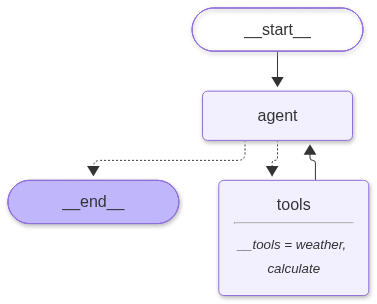

In [39]:
from IPython.display import Image, display

display(Image(react_graph.get_graph().draw_mermaid_png()))

In [40]:
config = {"configurable": {"thread_id": "student-1"}}

result = react_graph.invoke(
    {"messages": [("user", "What is the weather in Seattle? Convert the temperature to Fahrenheit.")]},
    config)

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the weather in Seattle? Convert the temperature to Fahrenheit.
================================== Ai Message ==================================
Tool Calls:
  weather (call_1JfL4XNh26sxHaSIkf47HkyI)
 Call ID: call_1JfL4XNh26sxHaSIkf47HkyI
  Args:
    city: Seattle
================================= Tool Message =================================
Name: weather

Rain, 10 C
================================== Ai Message ==================================

The weather in Seattle is rainy, and the temperature is 10 degrees Celsius. Let me convert that to Fahrenheit for you.
Tool Calls:
  calculate (call_NE5L8VLL6d1kEKfwtUyzvf9U)
 Call ID: call_NE5L8VLL6d1kEKfwtUyzvf9U
  Args:
    expression: (10 * 9/5) + 32
================================= Tool Message =================================
Name: calculate

50.0
================================== Ai Message ==================================

The temperature i

Because the checkpointer saved the conversation for the thread `student-1`, a follow-up question in the same thread can refer to the earlier messages. A different `thread_id` would start a new conversation without this history.

In [41]:
result = react_graph.invoke({"messages": [("user", "And how about Moscow? Is it warmer there?")]}, config)
print(result["messages"][-1].content)

The temperature in Moscow is 64.4 degrees Fahrenheit, which is warmer than the 50 degrees Fahrenheit in Seattle.


For common cases, it is not necessary to build the graph manually. LangChain 1.0 provides the function `create_agent()` (from `langchain.agents`), which builds a similar tool-calling agent graph in a single line, and supports additional *middleware* for summarization, human approval, and other harness features.

<a id="25.5.3-an-evaluator-optimizer-workflow"></a>

### 25.5.3 An Evaluator-Optimizer Workflow

Next, we implement the evaluator-optimizer pattern from Section 25.2.4 as a graph with a custom state. A `writer` node writes or revises a short explanation, and a `critic` node scores it from 1 to 10 and provides feedback, using structured output. The conditional edge after the critic either sends the draft back to the writer or finishes, when the score is at least 9 or after three iterations.

In [42]:
from typing import TypedDict

class WritingState(TypedDict):
    topic: str
    draft: str
    feedback: str
    score: int
    iterations: int

class Review(BaseModel):
    score: int = Field(description="Quality score from 1 (poor) to 10 (excellent)")
    feedback: str = Field(description="Specific suggestions for improvement")

critic_model = chat_model.with_structured_output(Review, method="function_calling")

def writer(state: WritingState):
    request = f"Explain '{state['topic']}' to a first-year student in under 100 words."
    if state.get("feedback"):
        request += f"\n\nPrevious draft:\n{state['draft']}\n\nRevise it using this feedback:\n{state['feedback']}"
    draft = chat_model.invoke(request).content
    return {"draft": draft, "iterations": state.get("iterations", 0) + 1}

def critic(state: WritingState):
    review = critic_model.invoke(
        f"You are a strict reviewer. Score this explanation of '{state['topic']}' for a first-year "
        f"student. Check accuracy, clarity, and use of an intuitive example. Reserve scores of 9 "
        f"and 10 for explanations that cannot be improved, and always give at least one concrete "
        f"suggestion.\n\n{state['draft']}")
    print(f"Iteration {state['iterations']}: score = {review.score}")
    return {"score": review.score, "feedback": review.feedback}

def should_continue(state: WritingState):
    if state["score"] >= 9 or state["iterations"] >= 3:
        return END
    return "writer"

builder = StateGraph(WritingState)
builder.add_node("writer", writer)
builder.add_node("critic", critic)
builder.add_edge(START, "writer")
builder.add_edge("writer", "critic")
builder.add_conditional_edges("critic", should_continue, ["writer", END])
writing_graph = builder.compile()

final_state = writing_graph.invoke({"topic": "gradient descent"})
print("\nFINAL DRAFT:\n", final_state["draft"])

Iteration 1: score = 8
Iteration 2: score = 8
Iteration 3: score = 8

FINAL DRAFT:
 Gradient descent is a method to find the minimum value of a function. Imagine you're on a mountain and want to reach the lowest point. The gradient is a vector that points in the direction of the steepest increase of the function. Gradient descent involves walking downhill in the direction opposite to the gradient. The learning rate determines the size of the steps you take. You keep taking steps proportional to the steepness until you reach the bottom. However, be aware that you might get stuck in a local minimum, which isn't the lowest point overall. This method is useful for solving problems like fitting a line to data points.


<a id="25.6-crewai"></a>

## 25.6 CrewAI

**CrewAI** is an open-source framework for building multi-agent systems in which agents play specific roles, similarly to a team of employees. It offers a higher level of abstraction than LangGraph, and instead of defining nodes and edges, the developer describes *who* the agents are and *what* tasks need to be done.

The main CrewAI concepts are:

- **Agent**: Defined by a `role`, a `goal`, and a `backstory`, which are used to build the agent's system prompt. Agents can have tools and their own LLM.
- **Task**: A unit of work with a `description`, an `expected_output`, and the agent responsible for it. Tasks can receive the outputs of other tasks as `context`.
- **Crew**: A team of agents and a list of tasks, executed with a **process**. In a *sequential* process, tasks run in order, and the output of each task is passed to the next. In a *hierarchical* process, a manager agent (or manager LLM) assigns tasks to the agents and validates the results.
- **Flows**: An event-driven layer for building production workflows that combine regular Python code with crews.

In the example below, we create a crew of two agents: (1) a data analyst who designs an analysis plan, and (2) a technical writer who turns the plan into a short report.

Note that installing `crewai` in Colab may upgrade some pre-installed packages, and if a warning is displayed, restart the session before running the cells.

In [43]:
!pip install -q crewai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
bigframes 2.51.0 requires rich<14,>=12.4.4, but you have rich 14.3.4 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


CrewAI connects to LLMs through the LiteLLM library. The prefix `openai/` in the model name indicates an OpenAI-compatible API, and `base_url` points it to the Hugging Face router.

In [44]:
from crewai import Agent, Task, Crew, Process, LLM

crew_llm = LLM(model=f"openai/{MODEL_ID}", base_url=HF_BASE_URL, api_key=token, temperature=0.3,
               context_window_size=32768)   # Qwen2.5-72B context length (CrewAI cannot detect it)

analyst = Agent(
    role="Senior Data Analyst",
    goal="Design a sound, step-by-step analysis plan for {problem}",
    backstory="You have ten years of experience in applied machine learning, and you are known "
              "for choosing simple baselines first and for careful validation.",
    llm=crew_llm,
    verbose=True)

writer = Agent(
    role="Technical Writer",
    goal="Turn analysis plans into clear reports for non-technical stakeholders",
    backstory="You write concise, jargon-free documents for business managers.",
    llm=crew_llm,
    verbose=True)

plan_task = Task(
    description="Create an analysis plan for this problem: {problem}. Cover data collection, "
                "features, candidate models, and evaluation metrics.",
    expected_output="A numbered plan with 5 to 7 steps.",
    agent=analyst)

report_task = Task(
    description="Write a one-page report explaining the analysis plan to the city council.",
    expected_output="A report in markdown with a title, a short introduction, and the plan in plain language.",
    agent=writer,
    context=[plan_task])   # receives the output of plan_task

crew = Crew(agents=[analyst, writer], tasks=[plan_task, report_task], process=Process.sequential)

The `{problem}` placeholders in the agent goals and task descriptions are filled with the `inputs` dictionary passed to the crew. Since a notebook already runs an event loop, recent versions of CrewAI require the asynchronous method `kickoff_async()`, which is awaited, instead of `kickoff()`. With `verbose=True`, CrewAI prints the reasoning and the output of each agent.

In [45]:
result = await crew.kickoff_async(inputs={"problem": "predicting which streets in Moscow, Idaho need snow plowing first"})

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Senior Data Analyst                                                                                     │
│                                                                                                                 │
│  Task: Create an analysis plan for this problem: predicting which streets in Moscow, Idaho need snow plowing    │
│  first. Cover data collection, features, candidate models, and evaluation metrics.                              │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Senior Data Analyst                                                                                     │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### Analysis Plan for Predicting Which Streets in Moscow, Idaho Need Snow Plowing First                        │
│                                                                                                                 │
│  1. **Data Collection and Preprocessing:**                                                                      │
│     - **Weather Data:** Collect historical weather data for Moscow, Idaho, including snowfall amounts,          │
│  temperature, and precipitation types. Sources can include the National Oceanic and Atmospheric Administration  │
│  (NOAA) and local weather stations.                                                                             │
│     - **Streets Data:** Obtain a detailed map of Moscow, Idaho, including street names, lengths, and types      │
│  (e.g., residential, commercial, arterial). This data can be sourced from the city's GIS department.            │
│     - **Traffic Data:** Gather traffic volume data for different streets, which can be obtained from traffic    │
│  sensors or historical traffic studies.                                                                         │
│     - **Incident Data:** Collect data on past snow-related incidents, such as accidents, blocked roads, and     │
│  service calls. This information can be obtained from the city's emergency services and public works            │
│  department.                                                                                                    │
│     - **Demographic Data:** Include population density and demographic information for different areas of the   │
│  city, which can be sourced from the U.S. Census Bureau.                                                        │
│     - **Preprocessing:** Clean and preprocess the data to handle missing values, outliers, and                  │
│  inconsistencies. Standardize the data formats and units.                                                       │
│                                                                                                                 │
│  2. **Feature Engineering:**                                                                                    │
│     - **Snowfall Intensity:** Create features based on the amount of snowfall, including cumulative snowfall    │
│  over the past 24 hours and the rate of snowfall.                                                               │
│     - **Street Characteristics:** Extract features such as street length, width, and type. Categorize streets   │
│  into residential, commercial, and arterial.                                                                    │
│     - **Traffic Volume:** Use traffic volume data to create features that indicate the level of traffic on      │
│  each street.                                                                                                   │
│     - **Incident History:** Incorporate features that reflect the frequency and severity of past snow-related   │
│  incidents on each street.                                                                                      │
│     - **Population Density:** Use demographic data to create features that reflect the population density of    │
│  the areas surrounding each street.                                                                             │
│     - **Time of Day and Day of Week:** Include features

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Technical Writer                                                                                        │
│                                                                                                                 │
│  Task: Write a one-page report explaining the analysis plan to the city council.                                │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Technical Writer                                                                                        │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  # Analysis Plan for Predicting Snow Plowing Needs in Moscow, Idaho                                             │
│                                                                                                                 │
│  ## Introduction                                                                                                │
│  The city of Moscow, Idaho, faces significant challenges during winter months due to heavy snowfall. To ensure  │
│  the safety and mobility of residents, it is crucial to prioritize which streets need snow plowing first. This  │
│  report outlines a comprehensive analysis plan to predict the streets that require immediate attention.         │
│                                                                                                                 │
│  ## Analysis Plan                                                                                               │
│                                                                                                                 │
│  ### Data Collection and Preprocessing                                                                          │
│  1. **Weather Data:** We will gather historical weather data, including snowfall amounts, temperature, and      │
│  precipitation types, from sources like the National Oceanic and Atmospheric Administration (NOAA) and local    │
│  weather stations.                                                                                              │
│  2. **Streets Data:** A detailed map of Moscow, Idaho, will be obtained from the city's GIS department,         │
│  including street names, lengths, and types (residential, commercial, arterial).                                │
│  3. **Traffic Data:** Traffic volume data will be collected from traffic sensors or historical traffic          │
│  studies.                                                                                                       │
│  4. **Incident Data:** Past snow-related incidents, such as accidents and blocked roads, will be sourced from   │
│  the city's emergency services and public works department.                                                     │
│  5. **Demographic Data:** Population density and demographic information will be obtained from the U.S. Census  │
│  Bureau.                                                                                                        │
│  6. **Preprocessing:** The data will be cleaned to handle missing values, outliers, and inconsistencies, and    │
│  standardized for consistent analysis.                                                                          │
│                                                                                                                 │
│  ### Feature Engineering                                                                                        │
│  1. **Snowfall Intensity:** Features will be created based on the amount of snowfall, including cumulative      │
│  snowfall over the past 24 hours and the rate of snowfall.                                                      │
│  2. **Street Characteristics:** Features will include street length, width, and type, with streets categorized  │
│  as residential, commercial, or arterial.                                                                       │
│  3. **Traffic Volume:** Features will reflect the level

In [46]:
from IPython.display import Markdown

Markdown(result.raw)

# Analysis Plan for Predicting Snow Plowing Needs in Moscow, Idaho

## Introduction
The city of Moscow, Idaho, faces significant challenges during winter months due to heavy snowfall. To ensure the safety and mobility of residents, it is crucial to prioritize which streets need snow plowing first. This report outlines a comprehensive analysis plan to predict the streets that require immediate attention.

## Analysis Plan

### Data Collection and Preprocessing
1. **Weather Data:** We will gather historical weather data, including snowfall amounts, temperature, and precipitation types, from sources like the National Oceanic and Atmospheric Administration (NOAA) and local weather stations.
2. **Streets Data:** A detailed map of Moscow, Idaho, will be obtained from the city's GIS department, including street names, lengths, and types (residential, commercial, arterial).
3. **Traffic Data:** Traffic volume data will be collected from traffic sensors or historical traffic studies.
4. **Incident Data:** Past snow-related incidents, such as accidents and blocked roads, will be sourced from the city's emergency services and public works department.
5. **Demographic Data:** Population density and demographic information will be obtained from the U.S. Census Bureau.
6. **Preprocessing:** The data will be cleaned to handle missing values, outliers, and inconsistencies, and standardized for consistent analysis.

### Feature Engineering
1. **Snowfall Intensity:** Features will be created based on the amount of snowfall, including cumulative snowfall over the past 24 hours and the rate of snowfall.
2. **Street Characteristics:** Features will include street length, width, and type, with streets categorized as residential, commercial, or arterial.
3. **Traffic Volume:** Features will reflect the level of traffic on each street.
4. **Incident History:** Features will capture the frequency and severity of past snow-related incidents.
5. **Population Density:** Features will reflect the population density of the areas surrounding each street.
6. **Time of Day and Day of Week:** Features will capture the time of day and day of the week, as these can affect the urgency of plowing needs.

### Exploratory Data Analysis (EDA)
1. **Descriptive Statistics:** Summary statistics will be calculated for each feature to understand the data distribution and identify outliers.
2. **Correlation Analysis:** Relationships between features and the target variable (need for snow plowing) will be identified through correlation analysis.
3. **Visualization:** Visualizations such as heat maps, scatter plots, and box plots will be created to explore patterns in the data.

### Model Selection
1. **Baseline Model:** A simple logistic regression model will be used to establish a baseline performance.
2. **Decision Trees:** Decision trees will capture non-linear relationships and interactions between features.
3. **Random Forest:** A random forest model will improve prediction accuracy and handle overfitting.
4. **Gradient Boosting Machines (GBM):** GBM will enhance model performance by combining multiple weak learners.
5. **Neural Networks:** If the dataset is large and complex, neural networks will be explored to capture intricate patterns.

### Model Training and Validation
1. **Train-Test Split:** The data will be split into training and testing sets using a 70-30 or 80-20 ratio.
2. **Cross-Validation:** K-fold cross-validation will ensure the model generalizes well to unseen data.
3. **Hyperparameter Tuning:** Grid search or random search will be used to optimize the model's performance.
4. **Feature Importance:** Feature importance will be analyzed to understand which features are most influential in predicting the need for snow plowing.

### Evaluation Metrics
1. **Accuracy:** The overall accuracy of the model in correctly predicting the need for snow plowing will be measured.
2. **Precision and Recall:** Precision will evaluate the model's performance in correctly identifying streets that need plowing, while recall will measure the proportion of actual plowing needs that are correctly identified.
3. **F1 Score:** The F1 score will balance precision and recall, especially if the dataset is imbalanced.
4. **ROC-AUC:** The Area Under the Receiver Operating Characteristic Curve (ROC-AUC) will evaluate the model's ability to distinguish between streets that need plowing and those that do not.

### Deployment and Monitoring
1. **Model Deployment:** The final model will be deployed in a production environment to predict which streets need snow plowing first.
2. **Real-Time Data Integration:** A system will be set up to continuously collect and update real-time data, such as current weather conditions and traffic volume.
3. **Performance Monitoring:** The model's performance will be regularly monitored using the evaluation metrics, and the model will be retrained as needed to ensure accuracy and relevance.
4. **Feedback Loop:** A feedback loop will be implemented to collect user feedback and use it to improve the model over time.

By following this plan, we can build a robust and accurate model to predict which streets in Moscow, Idaho, need snow plowing first, ensuring efficient and effective snow removal operations.

<a id="25.7-autogen"></a>

## 25.7 AutoGen

**AutoGen** is a multi-agent framework developed by Microsoft Research, which popularized the idea of building applications as *conversations between agents*. Agents exchange messages, and a team of agents collaborates by taking turns in a group chat until a termination condition is met.

The current AutoGen architecture (version 0.4 and later) has several layers. The high-level **AgentChat** API, which we will use, provides:

- **AssistantAgent**: An LLM-based agent with a system message and optional tools.
- **Teams**: Ways for agents to collaborate. `RoundRobinGroupChat` lets agents speak in a fixed order, while `SelectorGroupChat` uses an LLM to choose the next speaker.
- **Termination conditions**: Rules that end the conversation, e.g., when a message contains a specific word, or after a maximum number of messages.

AutoGen is asynchronous, so teams are run with `await`. Note that last year Microsoft announced the **Microsoft Agent Framework**, which merges AutoGen with Semantic Kernel and is the recommended path for new enterprise projects, while AutoGen remains available and is widely used in research. The multi-agent conversation concepts are the same in both frameworks.

In [47]:
!pip install -q "autogen-agentchat" "autogen-ext[openai]"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-language 2.22.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-functions 1.25.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-spanner 3.71.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-monitoring 2.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
googleapis-common-protos 1.76.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatib

The `OpenAIChatCompletionClient` connects to OpenAI-compatible APIs. For models that are not from OpenAI, AutoGen requires the `model_info` dictionary, which describes the capabilities of the model.

In [48]:
from autogen_agentchat.agents import AssistantAgent
from autogen_agentchat.teams import RoundRobinGroupChat
from autogen_agentchat.conditions import TextMentionTermination, MaxMessageTermination
from autogen_agentchat.ui import Console
from autogen_ext.models.openai import OpenAIChatCompletionClient
import warnings

# AutoGen warns that it does not recognize the Qwen model name; the warning is harmless
warnings.filterwarnings("ignore", message="Resolved model mismatch")

model_client = OpenAIChatCompletionClient(
    model=MODEL_ID, base_url=HF_BASE_URL, api_key=token,
    model_info={"vision": False, "function_calling": True, "json_output": True,
                "family": "unknown", "structured_output": True})

**A Single Agent with a Tool**

In AutoGen, plain Python functions can be passed directly as tools, and the function signature and docstring are used for the tool description.

In [49]:
assistant = AssistantAgent(
    name="assistant",
    model_client=model_client,
    tools=[get_weather],
    system_message="You are a helpful assistant. Use tools when needed.",
    reflect_on_tool_use=True)   # summarize the tool result in natural language

result = await Console(assistant.run_stream(task="Is it raining in Seattle?"))

---------- TextMessage (user) ----------
Is it raining in Seattle?
---------- ToolCallRequestEvent (assistant) ----------
[FunctionCall(id='call_O7KnP5iXpOfpvCoEkFz56KjG', arguments='{"city": "Seattle"}', name='get_weather')]
---------- ToolCallExecutionEvent (assistant) ----------
[FunctionExecutionResult(content='Rain, 10 C', name='get_weather', call_id='call_O7KnP5iXpOfpvCoEkFz56KjG', is_error=False)]
---------- TextMessage (assistant) ----------
It is currently raining in Seattle, and the temperature is 10°C.


**A Team of Agents**

Next, we create a team of two agents that collaborate in a round-robin conversation: (1) a programmer who writes Python code, and (2) a reviewer who checks the code and replies "APPROVE" when it is acceptable. The conversation ends when the word "APPROVE" appears, or after 6 messages, whichever comes first. Combining termination conditions with `|` (logical OR) is a recommended guardrail, since multi-agent conversations can otherwise continue indefinitely.

In [50]:
programmer = AssistantAgent(
    name="programmer",
    model_client=model_client,
    system_message="You are a Python programmer. Write clean, documented code. "
                   "Revise your code based on the reviewer's feedback.")

reviewer = AssistantAgent(
    name="reviewer",
    model_client=model_client,
    system_message="You are a code reviewer. Check the code for bugs, edge cases, and readability. "
                   "Give concrete feedback, but do not write the code yourself. "
                   "Reply with APPROVE only when no further changes are needed.")

termination = TextMentionTermination("APPROVE") | MaxMessageTermination(6)
team = RoundRobinGroupChat([programmer, reviewer], termination_condition=termination)

result = await Console(team.run_stream(
    task="Write a function that computes the moving average of a list of numbers with a given window size."))

---------- TextMessage (user) ----------
Write a function that computes the moving average of a list of numbers with a given window size.
---------- TextMessage (programmer) ----------
Certainly! Below is a Python function that computes the moving average of a list of numbers with a given window size. I've included comments and a docstring to explain the function.

```python
def moving_average(data, window_size):
    """
    Computes the moving average of a list of numbers with a given window size.

    :param data: List of numerical data points.
    :param window_size: The size of the moving window.
    :return: A list of moving averages.
    """
    if not data or window_size <= 0:
        raise ValueError("Data list must not be empty and window size must be positive.")

    if window_size > len(data):
        raise ValueError("Window size cannot be larger than the length of the data list.")

    moving_averages = []
    for i in range(len(data) - window_size + 1):
        window = d

Notice that, although the system message instructs the reviewer not to write code, the reviewer rewrote the function itself in both of its reviews, and in the second review it approved its own refined version in the same message. Instructions in the system prompt are followed only approximately, and an agent tends to approve its own work (self-preferential bias). When a process must be followed reliably, it is better to enforce it in code, e.g., with a workflow that limits what each agent can do, or with a termination condition that only accepts a message containing nothing but "APPROVE".

In [51]:
await model_client.close()

<a id="25.8-choosing-a-framework"></a>

## 25.8 Choosing a Framework

The following table compares the frameworks covered in Lectures 24 and 25.

| Framework | Abstraction level | Core idea | Strengths | Typical use |
|-----------|-------------------|-----------|-----------|-------------|
| No framework (plain Python) | Lowest | Agent loop written by hand | Full control, no dependencies, easy to debug | Simple agents, learning, production systems with custom needs |
| smolagents | Low | Code agents that write Python | Lightweight, transparent, open models | Prototyping, research, open-source agents |
| LangChain | Medium | Standard components and chains | Huge ecosystem of integrations | RAG pipelines, model and tool abstraction |
| LangGraph | Low to medium | State graph with nodes and edges | Explicit control, persistence, human-in-the-loop | Production agents and complex workflows |
| CrewAI | High | Role-playing agents in a crew | Fast to set up, readable code | Multi-agent business and research workflows |
| AutoGen | Medium | Conversations between agents | Flexible multi-agent dialogue | Multi-agent research and prototyping |

Some practical guidelines for choosing an approach:

- **Start without a framework.** Many useful applications need only a few LLM calls, and the code in Sections 25.2 and 25.3 is sufficient. Understanding what happens under the hood also makes debugging framework-based code much easier.
- **Use LangGraph** when you need explicit control over complex flows, long-running tasks, persistence, or human approval steps.
- **Use CrewAI** when the problem naturally decomposes into roles, and fast development is more important than fine-grained control.
- **Use AutoGen (or Microsoft Agent Framework)** when the solution is naturally expressed as a dialogue between agents, or when integrating with the Microsoft ecosystem.
- **Consider single-agent solutions first.** Multi-agent systems use many more tokens, and errors can propagate between agents. They are most beneficial when subtasks are independent and can run in parallel, or when separate contexts are needed for different subtasks.

Frameworks evolve very quickly, and their APIs change often. The concepts covered in this lecture like workflows, tool calling, harness, memory, state, multi-agent coordination are applicable even with changes in libraries.

<a id="25.9-production-considerations"></a>

## 25.9 Production Considerations

Moving an agent from a notebook into production introduces additional engineering concerns.

**Observability and Tracing**

Agents can take many steps, and a failure at any step can lead to a wrong final answer. Tracing tools record every LLM call, tool call, input, output, latency, and token count in a hierarchical view, which is essential for debugging. Examples include LangSmith, Langfuse, Arize Phoenix, and tools based on the OpenTelemetry standard.

**Evaluation**

Agents should be evaluated on a set of representative tasks, both for the final result (was the task completed correctly?) and for the trajectory (did the agent use the right tools, and how many steps did it take?). We will study evaluation pipelines in Lecture 27.

**Cost and Latency**

Each step of an agent loop resends the expanding conversation to the model, so token usage can grow quickly. Common strategies include setting step and token budgets, using smaller models for simple steps (routing), prompt caching, and compacting the context. Prompt caching is particularly effective for agents, as if the prompt starts with a *stable prefix* that does not change between steps (the system prompt, tool descriptions, and a summary of the workspace), followed by the parts that change (memory, recent history, and the latest request), the LLM provider can reuse the computation for the prefix instead of processing it again at every step, which reduces both cost and latency [12].

**Reliability**

LLM APIs can fail or time out, and tools can return errors. Production harnesses implement retries with exponential backoff, fallback models, timeouts, and validation of tool inputs and outputs. Persistence (as in LangGraph's checkpointers) allows long-running tasks to resume after a failure instead of starting over.

**Security**

Agents that read external content (web pages, emails, documents) are vulnerable to **prompt injection**, where malicious text instructs the agent to perform unintended actions, such as sending private data to an attacker. Mitigations include following the principle of least privilege for tools and credentials, sandboxing code execution, requiring human approval for sensitive or irreversible actions, and separating trusted instructions from untrusted data. In multi-agent systems, a related approach is *quarantine*, where the agents that read untrusted content are not allowed to perform high-privilege actions, which are instead performed by separate agents that act only on the information extracted from that content [14].

**Self-Improving Harnesses**

Since a harness is code that combines prompts, tools, control flow, and memory, the harness itself can be optimized automatically [9]. For instance, AFlow represents workflows as graphs of LLM calls and searches for better-performing graphs, and the Darwin Gödel Machine lets a coding agent edit its own harness code and keeps the changes that improve its benchmark score. With the latter approach, the success rate on the SWE-bench Verified coding benchmark increased from 20% to 50%. Such methods work best when the results can be checked automatically, e.g., by running tests. They also introduce a new risk, because an agent that can modify its own harness may learn to exploit its evaluation (e.g., by overfitting to the tests) instead of solving the task, which is a form of reward hacking. Therefore, the evaluators, tests, and permission controls must be kept outside the part of the system that the agent is allowed to change.

## References

1. Building Effective Agents, by Erik Schluntz and Barry Zhang, Anthropic, available at [https://www.anthropic.com/engineering/building-effective-agents](https://www.anthropic.com/engineering/building-effective-agents).
2. Effective Context Engineering for AI Agents, Anthropic, available at [https://www.anthropic.com/engineering/effective-context-engineering-for-ai-agents](https://www.anthropic.com/engineering/effective-context-engineering-for-ai-agents).
3. Model Context Protocol Documentation, available at [https://modelcontextprotocol.io](https://modelcontextprotocol.io).
4. LangChain Documentation, available at [https://docs.langchain.com](https://docs.langchain.com).
5. LangGraph Documentation, available at [https://docs.langchain.com/oss/python/langgraph/overview](https://docs.langchain.com/oss/python/langgraph/overview).
6. CrewAI Documentation, available at [https://docs.crewai.com](https://docs.crewai.com).
7. AutoGen Documentation, Microsoft, available at [https://microsoft.github.io/autogen](https://microsoft.github.io/autogen).
8. Hugging Face Inference Providers Documentation, available at [https://huggingface.co/docs/inference-providers](https://huggingface.co/docs/inference-providers).
9. Harness Engineering for Self-Improvement, by Lilian Weng, Lil'Log, available at [https://lilianweng.github.io/posts/2026-07-04-harness/](https://lilianweng.github.io/posts/2026-07-04-harness/).
10. Unrolling the Codex Agent Loop, OpenAI, available at [https://openai.com/index/unrolling-the-codex-agent-loop/](https://openai.com/index/unrolling-the-codex-agent-loop/).
11. Agentic Context Engineering: Evolving Contexts for Self-Improving Language Models, by Zhang et al., available at [https://arxiv.org/abs/2510.04618](https://arxiv.org/abs/2510.04618).
12. Components of a Coding Agent, by Sebastian Raschka, Ahead of AI, available at [https://magazine.sebastianraschka.com/p/components-of-a-coding-agent](https://magazine.sebastianraschka.com/p/components-of-a-coding-agent).
13. Mini Coding Agent, by Sebastian Raschka, GitHub repository, available at [https://github.com/rasbt/mini-coding-agent](https://github.com/rasbt/mini-coding-agent).
14. A Harness for Every Task: Dynamic Workflows in Claude Code, by Thariq, X post, available at [https://x.com/trq212/status/2061907337154367865](https://x.com/trq212/status/2061907337154367865).

[BACK TO TOP](#top)